In [ ]:
import requests
import csv
from datetime import datetime
from pathlib import Path
import yaml
import os

NAVIDROME_URL = "http://192.168.1.99:4533"
if "__file__" in globals():
    BASE_DIR = Path(__file__).resolve().parent
else:
    BASE_DIR = Path(os.getcwd())

config = {}

local_config = BASE_DIR / "config.local.yaml"

with open(local_config, "r") as f:
    config.update(yaml.safe_load(f) or {})

navidrome_cfg = config.get("navidrome", {})

USER = navidrome_cfg.get("user")
PASSWORD = navidrome_cfg.get("password")

def fetch_navidrome_stats():
    # Autenticación
    # Stats generales
    r2 = requests.get(
        f"{NAVIDROME_URL}/rest/getAlbumList2",
        params={
            "u": USER,
            "p": PASSWORD,
            "v": "1.16.1",
            "c": "stats",
            "f": "json",
            "type": "newest",
            "size": 1
        }
    )
    
#     data = r2.json()['subsonic-response']
#     total_albums = data.get('albumList2', {}).get('album', [])
   
#     # Guardar en CSV con fecha
#     stats_file = Path('.') / 'data' / 'navidrome_stats.csv'
#     file_exists = stats_file.exists()
    
#     with open(stats_file, 'a', newline='') as f:
#         writer = csv.writer(f)
#         if not file_exists:
#             writer.writerow(['date', 'albums', 'tracks'])
#         writer.writerow([datetime.now().strftime('%Y-%m-%d'), len(total_albums), ''])

# if __name__ == "__main__":
#     fetch_navidrome_stats()

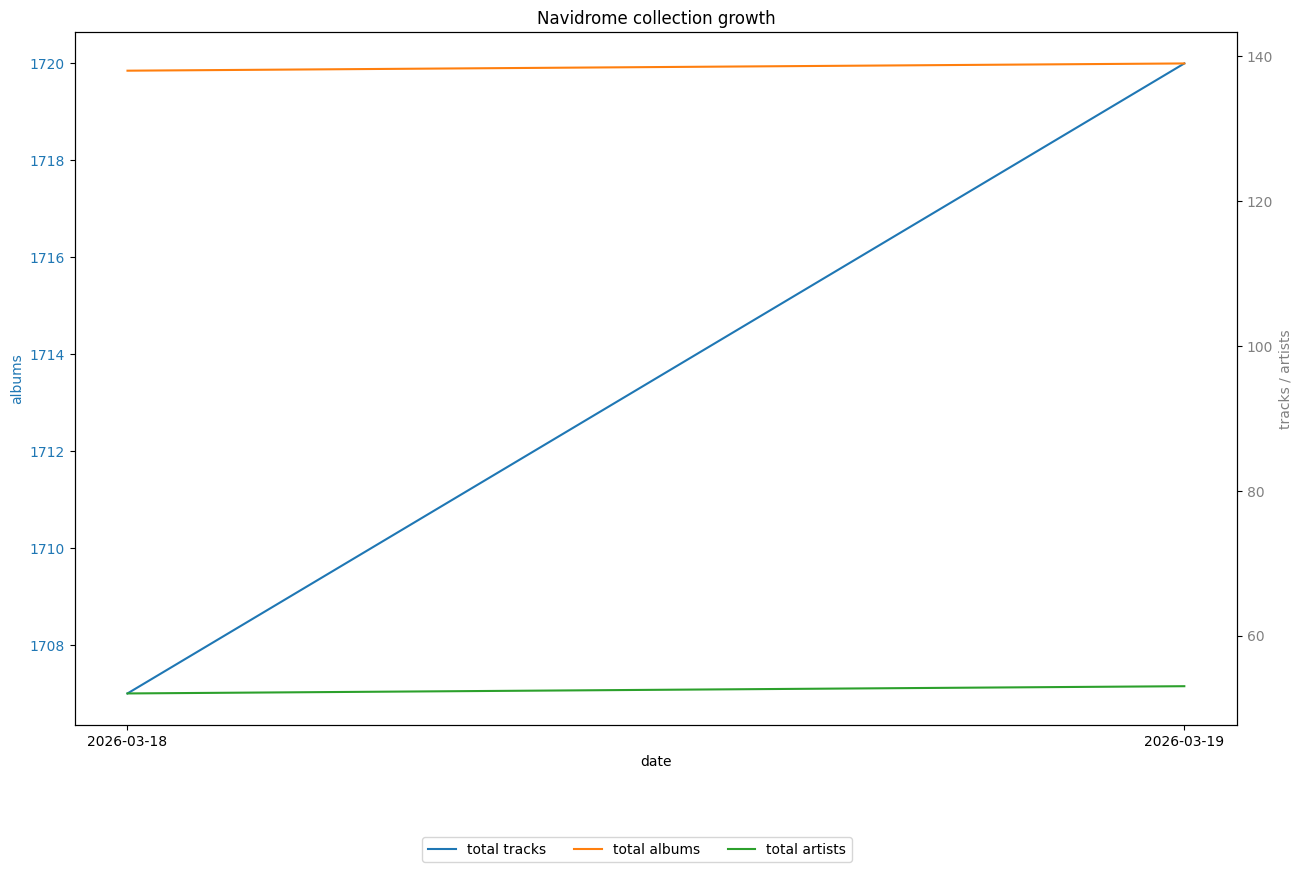

In [6]:
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Leer el archivo CSV
stats_file = Path('.') / 'data' / 'navidrome_stats.csv'
df = pd.read_csv(stats_file)
data = df.values

x = data[:, 0]  # Primera columna
y1 = data[:, 1]  # albums
y2 = data[:, 2]  # tracks
y3 = data[:, 3]  # artists

fig, ax1 = plt.subplots(figsize=(15, 9) )

ax1.plot(x, y2, label='total tracks', color='tab:blue')
ax1.set_xlabel('date')
ax1.set_ylabel('albums', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(x, y1, label='total albums', color='tab:orange')
ax2.plot(x, y3, label='total artists', color='tab:green')
ax2.set_ylabel('tracks / artists', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)
plt.title('Navidrome collection growth')
plt.show()